In [1]:
import pandas as pd
import numpy as np
import random
import pyomo.environ as pyo
from pyomo.environ import *
from pyomo.environ import SolverFactory
import yfinance as yf
from pathlib import Path
import os
import matplotlib.pyplot as plt


In [2]:
anos = ['2025-12-31',
 '2024-12-31',
 '2023-12-31',
 '2022-12-31',
 '2021-12-31',
 '2020-12-31',
 '2019-12-31',
 '2018-12-31',
 '2017-12-31',
 '2016-12-31',
 '2015-12-31',
 ]
anos.sort(reverse=False)
anos

['2015-12-31',
 '2016-12-31',
 '2017-12-31',
 '2018-12-31',
 '2019-12-31',
 '2020-12-31',
 '2021-12-31',
 '2022-12-31',
 '2023-12-31',
 '2024-12-31',
 '2025-12-31']

## LER OS RETORNOS, SCORE e SELIC

In [3]:

# Retornos

dfs = {}
for ano in anos:
    ano_usado = ano.split('-')[0]
    nome = f'df_ativos_{ano_usado}.csv'
    # caminho = Path('retornos_ativos_otimizacao') / nome
    dfs[ano_usado] = pd.read_csv('../../dados_retornos/otimizacao/ativos/'+nome)
    dfs[ano_usado]['date'] = pd.to_datetime(dfs[ano_usado]['date'])
    dfs[ano_usado] = dfs[ano_usado].set_index('date')
    dfs[ano_usado] = dfs[ano_usado].drop(columns=dfs[ano_usado].columns[(dfs[ano_usado] == 0).all()])
    print(ano,'-',len(dfs[ano_usado].columns))
    

2015-12-31 - 62
2016-12-31 - 67
2017-12-31 - 70
2018-12-31 - 70
2019-12-31 - 73
2020-12-31 - 73
2021-12-31 - 77
2022-12-31 - 77
2023-12-31 - 78
2024-12-31 - 78
2025-12-31 - 78


## Hiperparâmetros

In [4]:
vb_cardinalidade_max = 10
vb_cardinalidade_min = 10
vb_peso_maximo = 0.20
vb_peso_minimo = 0.02
vb_theta = 0.5

### Fazendo otimização ano a ano e comparando com o proximo ano

In [5]:
anos = ['2015-12-31', '2016-12-31', '2017-12-31', '2018-12-31', '2019-12-31', '2020-12-31', '2021-12-31', '2022-12-31', '2023-12-31', '2024-12-31', '2025-12-31']
print(anos)

['2015-12-31', '2016-12-31', '2017-12-31', '2018-12-31', '2019-12-31', '2020-12-31', '2021-12-31', '2022-12-31', '2023-12-31', '2024-12-31', '2025-12-31']


In [6]:
y = []

carteiras_anuais = {}

melhor_pesos = None
historico = []
carteiras_criadas = []
for a in anos:
    y.append(a.split('-')[0])

print("=-"*48)
print("Anos totais: ", y)
print("=-"*48)

storage_model_x = {}   # <<< dicionário vazio: no 1º ano todo peso anterior vira 0

for an in anos:
    ano = an.split("-")[0]
    print("COMEÇANDO ANO NOVO: ", ano)

    if 'model' in locals():
        del model
        print('Modelo Antigo deletado \n Iniciando Novo')
    else:
        print("Nao consta model")

    try:
        ano_um = int(ano)
        df_usado = dfs[str(ano_um)]
        retorno_usado = df_usado.copy()
        retorno_usado = (retorno_usado - retorno_usado.min())/(retorno_usado.max() - retorno_usado.min())
        print("Retornos atualizados")

        sigma_usado = retorno_usado.cov()
        print("Sigmas Atualizados")
        print("-----")
    except Exception as e:
        print("ERRRRRRRRRRRROR")
        print(e)

    print("# ------ CRIAÇÃO DO MODELO")
    print("## Carteira criada para o ano: ", int(ano)+1)
    print("## UTILIZANDO DADOS DE RETORNO DE: ", str(ano_um))
    print("## UTILIZANDO SIGMAS DO ANO DE: ", ano_um)

    # <<< lista de nomes deste ano, na ordem das colunas (= ordem dos índices do modelo)
    nomes_ativos = retorno_usado.columns.tolist()

    # <<< percorre os ativos ATUAIS e busca o peso do ano anterior; 0 se não existia
    pesos_anteriores = {nome: storage_model_x.get(nome, 0.0) for nome in nomes_ativos}

    print(f"## ATIVOS NO UNIVERSO: {len(nomes_ativos)} | COM PESO ANTERIOR > 0: "
          f"{sum(1 for v in pesos_anteriores.values() if v > 1e-8)}")

    model = pyo.ConcreteModel()

    #---------VARIÁVEIS-----------
    model.nome_ativos = pyo.Set(initialize=nomes_ativos)
    model.ativos = pyo.RangeSet(0, len(nomes_ativos)-1)
    model.dias = pyo.RangeSet(0, len(retorno_usado)-1)
    model.retornos_ativos = pyo.Param(model.dias, model.ativos,
                                      initialize=lambda model, dia, ativo: retorno_usado.iloc[dia, ativo])
    model.cardinalidade_valor_max = pyo.Param(initialize=vb_cardinalidade_max)
    model.cardinalidade_valor_min = pyo.Param(initialize=vb_cardinalidade_min)
    model.peso_maximo = pyo.Param(initialize=vb_peso_maximo)
    model.peso_minimo = pyo.Param(initialize=vb_peso_minimo)
    model.x = pyo.Var(model.ativos, bounds=(0, 1), domain=pyo.NonNegativeReals)
    model.y = pyo.Var(model.ativos, within=pyo.Binary)
    model.sigma = pyo.Param(model.ativos, model.ativos,
                            initialize=lambda model, a, b: sigma_usado.iloc[a, b])

    model.compra = pyo.Var(model.ativos, within=pyo.NonNegativeReals)
    model.venda = pyo.Var(model.ativos, within=pyo.NonNegativeReals)
    model.custo_transacao = pyo.Param(initialize=0.003)

    # <<< a ponte: índice -> nome -> peso anterior
    model.PESOS_ANTERIORES = pyo.Param(
        model.ativos,
        initialize=lambda model, a: pesos_anteriores[nomes_ativos[a]]
    )

    #=============================
    # Função Objetivo
    #=============================
    # <<< dois somatórios separados: covariância sobre (a,b), custo só sobre a
    def func_objetivo_1(model):
        risco = sum(model.x[a]*model.x[b]*model.sigma[a, b]
                    for a in model.ativos for b in model.ativos)
        custo = sum(model.custo_transacao * (model.compra[a] + model.venda[a])
                    for a in model.ativos)
        return risco + custo
    model.obj1 = pyo.Objective(rule=func_objetivo_1, sense=pyo.minimize)

    #=============================
    # RESTRIÇÕES
    #=============================
    def restr_compra_venda(model, a):
        return model.x[a] - model.PESOS_ANTERIORES[a] == model.compra[a] - model.venda[a]
    model.rule_compra_venda = pyo.Constraint(model.ativos, rule=restr_compra_venda)

    def restr_vinculo_x_y(model, a):
        return model.x[a] <= model.y[a]
    model.const_restr_vinculo_x_y = pyo.Constraint(model.ativos, rule=restr_vinculo_x_y)

    def rule_peso_maximo(model, a):
        return model.x[a] <= model.peso_maximo * model.y[a]
    model.const_peso_maximo = pyo.Constraint(model.ativos, rule=rule_peso_maximo)

    def rule_peso_minimo(model, a):
        return model.x[a] >= model.peso_minimo * model.y[a]
    model.const_peso_minimo = pyo.Constraint(model.ativos, rule=rule_peso_minimo)

    def soma_peso_1(model):
        return sum(model.x[a] for a in model.ativos) == 1
    model.const_soma_peso_1 = pyo.Constraint(rule=soma_peso_1)

    def cardinalidade_min(model):
        return sum(model.y[a] for a in model.ativos) >= model.cardinalidade_valor_min
    model.const_cardinalidade_total_min = pyo.Constraint(rule=cardinalidade_min)

    def cardinalidade_max(model):
        return sum(model.y[a] for a in model.ativos) <= model.cardinalidade_valor_max
    model.const_cardinalidade_total_max = pyo.Constraint(rule=cardinalidade_max)

    opt = SolverFactory('cplex', executable='C:\\Program Files\\IBM\\ILOG\\CPLEX_Studio_Community222\\cplex\\bin\\x64_win64\\cplex.exe')
    res = opt.solve(model, tee=False)

    melhor_pesos = {nomes_ativos[a]: pyo.value(model.x[a]) for a in model.ativos}

    # <<< diagnóstico: compra e venda totais devem bater (exceto no 1º ano)
    total_compra = sum(pyo.value(model.compra[a]) for a in model.ativos)
    total_venda = sum(pyo.value(model.venda[a]) for a in model.ativos)
    print(f"## TURNOVER -> compra: {total_compra:.4f} | venda: {total_venda:.4f}")

    # <<< guarda o dicionário de pesos direto, sem aninhar
    storage_model_x = melhor_pesos

    carteiras_anuais[int(ano_um)+1] = {
        'pesos': melhor_pesos,
    }
    print(f"{ano_um} -> {melhor_pesos}")
    print("+-="*30)

    if 'model' in locals():
        del model
        print('DELETADO DPS DO WHILE')

=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
Anos totais:  ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
COMEÇANDO ANO NOVO:  2015
Nao consta model
Retornos atualizados
Sigmas Atualizados
-----
# ------ CRIAÇÃO DO MODELO
## Carteira criada para o ano:  2016
## UTILIZANDO DADOS DE RETORNO DE:  2015
## UTILIZANDO SIGMAS DO ANO DE:  2015
## ATIVOS NO UNIVERSO: 62 | COM PESO ANTERIOR > 0: 0
## TURNOVER -> compra: 1.0000 | venda: 0.0000
2015 -> {'ABEV3': 0.0, 'ANIM3': 0.0, 'AXIA3': 0.0, 'AZZA3': 0.0, 'B3SA3': 0.0, 'BBAS3': 0.0, 'BBDC3': 0.0, 'BBDC4': 0.0, 'BBSE3': 0.0, 'BEEF3': 0.0, 'BRAP4': 0.0, 'BRKM5': 0.05279372405245159, 'CMIG4': 0.0, 'COGN3': 0.0, 'CPFE3': 0.0, 'CPLE3': 0.0, 'CSAN3': 0.0, 'CSMG3': 0.0, 'CSNA3': 0.0, 'CVCB3': 0.0, 'CYRE3': 0.0, 'DIRR3': 0.0, 'ECOR3': 0.0, 'EMBJ3': 0.06853022693986

In [13]:
carteiras_anuais

{2016: {'pesos': {'ABEV3': 0.0,
   'ANIM3': 0.0,
   'AXIA3': 0.0,
   'AZZA3': 0.0,
   'B3SA3': 0.0,
   'BBAS3': 0.0,
   'BBDC3': 0.0,
   'BBDC4': 0.0,
   'BBSE3': 0.0,
   'BEEF3': 0.0,
   'BRAP4': 0.0,
   'BRKM5': 0.05279372405245159,
   'CMIG4': 0.0,
   'COGN3': 0.0,
   'CPFE3': 0.0,
   'CPLE3': 0.0,
   'CSAN3': 0.0,
   'CSMG3': 0.0,
   'CSNA3': 0.0,
   'CVCB3': 0.0,
   'CYRE3': 0.0,
   'DIRR3': 0.0,
   'ECOR3': 0.0,
   'EMBJ3': 0.06853022693986345,
   'ENGI11': 0.15915386462087985,
   'EQTL3': 0.0,
   'EZTC3': 0.0,
   'FLRY3': 0.0,
   'GGBR4': 0.0,
   'GOAU4': 0.0,
   'HYPE3': 0.2,
   'ISAE4': 0.0,
   'ITSA4': 0.0,
   'ITUB3': 0.0,
   'ITUB4': 0.0,
   'JHSF3': 0.046847083975970816,
   'KLBN11': 0.0,
   'LREN3': 0.0,
   'MGLU3': 0.055861712988644646,
   'MOTV3': 0.0,
   'MRVE3': 0.0,
   'MULT3': 0.0,
   'PETR3': 0.0,
   'PETR4': 0.0,
   'POMO4': 0.0,
   'PRIO3': 0.07037190856659016,
   'PSSA3': 0.0585394431166259,
   'RADL3': 0.0,
   'RAPT4': 0.0,
   'RENT3': 0.0,
   'SANB11': 0.0,
  

In [8]:
linhas = []
for an in anos:
    an = int(an.split('-')[0])+1
    print(an)
    for k, v in carteiras_anuais[an]['pesos'].items():
        if v >= vb_peso_minimo :
            linhas.append({'ano': an, 'ativo': k, 'peso': round(v, 4)})

df_portfolios = pd.DataFrame(linhas)

# # visões instantâneas:
# df_portfolios[df_portfolios['ano'] == 2016].sort_values('peso', ascending=False)  # uma carteira
# df_portfolios.pivot(index='ativo', columns='ano', values='peso')                  # matriz ativo × ano
# df_portfolios.groupby('ativo')['ano'].count().sort_values(ascending=False)  


2016
2017
2018
2019
2020
2021
2022
2023
2024
2025
2026


In [9]:
print(df_portfolios[df_portfolios['ano'] == 2016].sort_values('peso', ascending=False))
print(df_portfolios[df_portfolios['ano'] == 2017].sort_values('peso', ascending=False))
print(df_portfolios[df_portfolios['ano'] == 2018].sort_values('peso', ascending=False))

    ano   ativo    peso
3  2016   HYPE3  0.2000
2  2016  ENGI11  0.1592
8  2016   SUZB3  0.1493
9  2016   USIM5  0.1386
6  2016   PRIO3  0.0704
1  2016   EMBJ3  0.0685
7  2016   PSSA3  0.0585
5  2016   MGLU3  0.0559
0  2016   BRKM5  0.0528
4  2016   JHSF3  0.0468
     ano   ativo    peso
10  2017  BPAC11  0.2000
19  2017   SUZB3  0.2000
13  2017  ENGI11  0.1555
14  2017   HYPE3  0.0870
17  2017   PRIO3  0.0704
12  2017   EMBJ3  0.0685
16  2017   MGLU3  0.0604
18  2017   PSSA3  0.0585
11  2017   BRKM5  0.0528
15  2017   JHSF3  0.0468
     ano   ativo    peso
29  2018   SUZB3  0.2000
23  2018  ENGI11  0.1467
22  2018   EMBJ3  0.1441
20  2018  BPAC11  0.1333
24  2018   HYPE3  0.0870
27  2018   PRIO3  0.0704
26  2018   MGLU3  0.0604
28  2018   PSSA3  0.0585
21  2018   BRKM5  0.0528
25  2018   JHSF3  0.0468


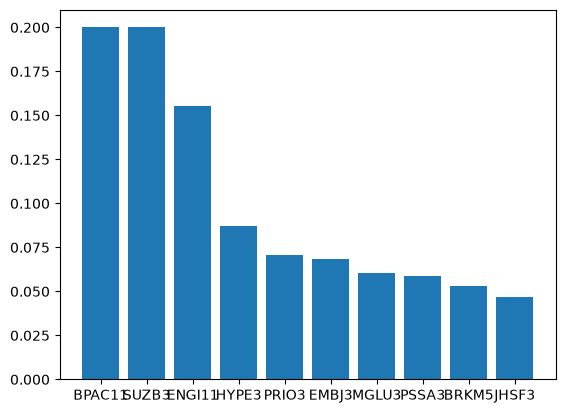

In [10]:
data = [2, 3, 3, 4, 5, 5, 5, 6, 7, 8]
y_ = [f'teste_{i}' for i in range(10)]

plt.bar(df_portfolios[df_portfolios['ano'] == 2017].sort_values('peso', ascending=False)['ativo'],height=df_portfolios[df_portfolios['ano'] == 2017].sort_values('peso', ascending=False)['peso'])

plt.show()

In [17]:
anos.append('2026-12-31')
anos

['2015-12-31',
 '2016-12-31',
 '2017-12-31',
 '2018-12-31',
 '2019-12-31',
 '2020-12-31',
 '2021-12-31',
 '2022-12-31',
 '2023-12-31',
 '2024-12-31',
 '2025-12-31',
 '2026-12-31']

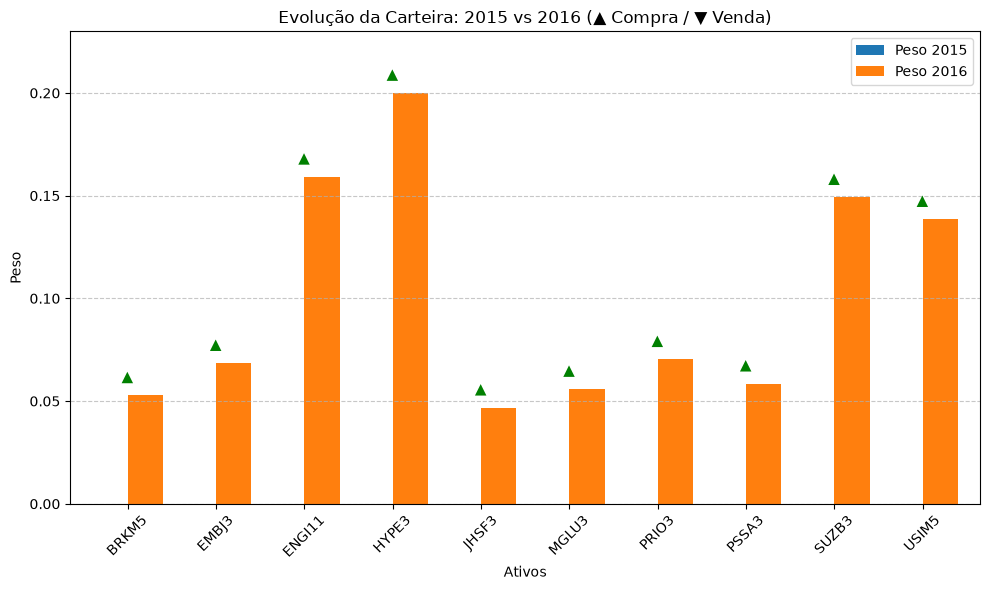

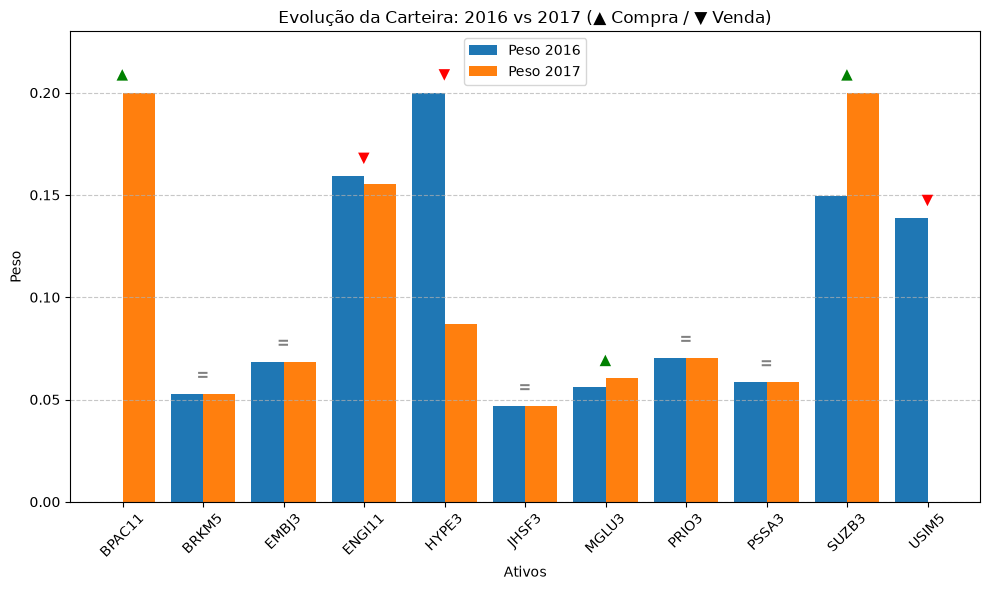

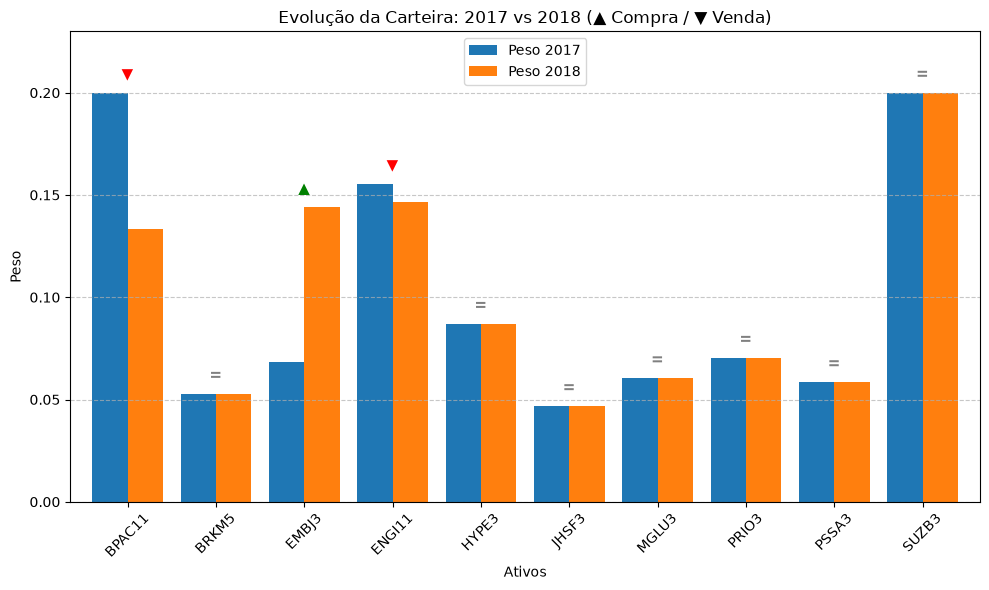

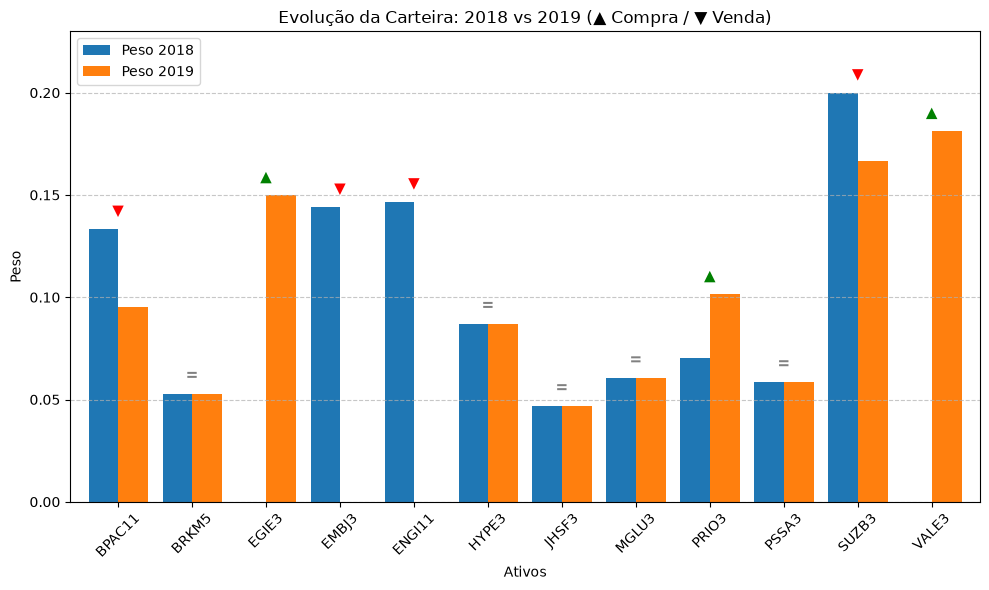

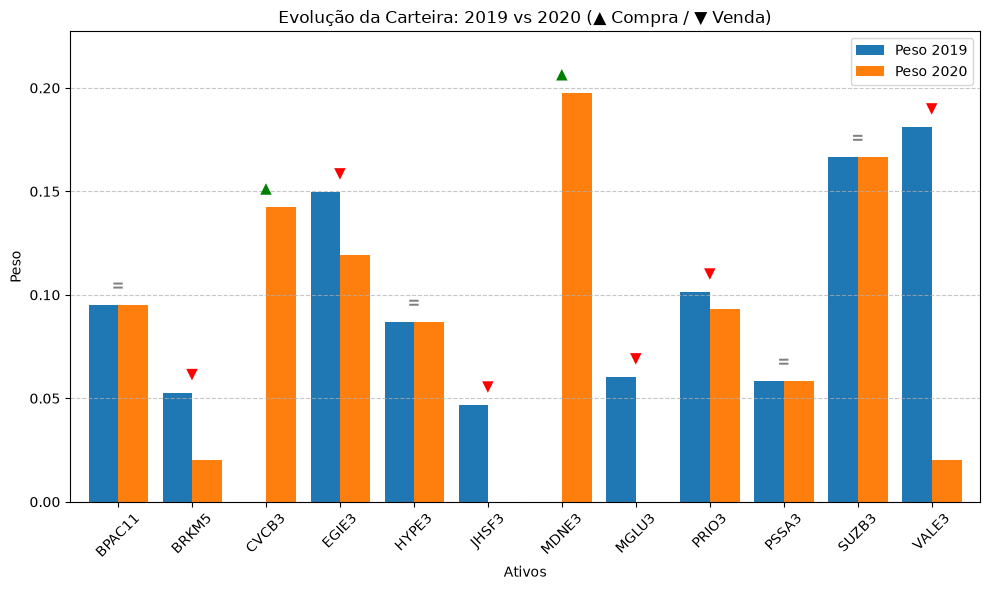

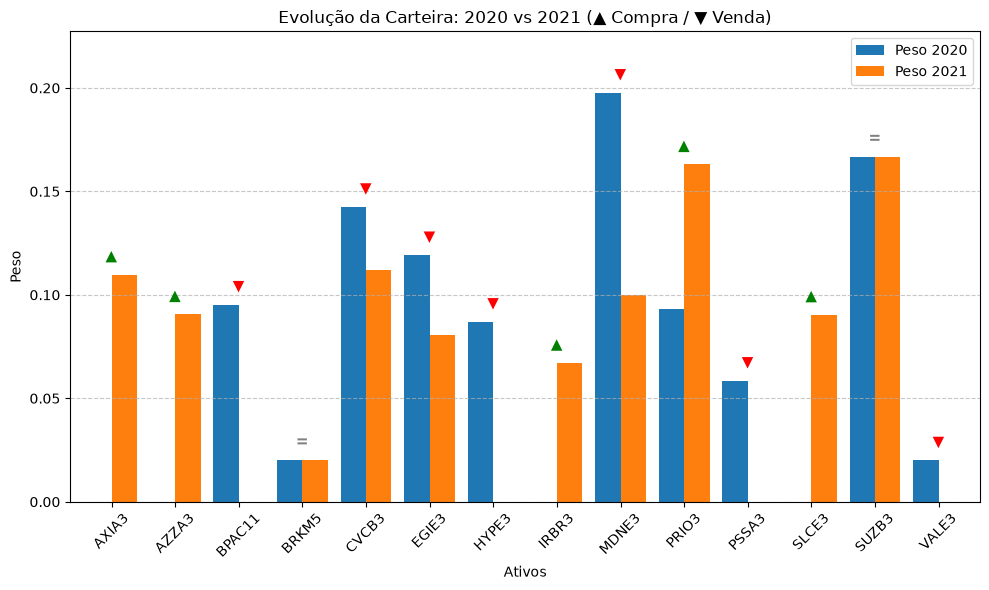

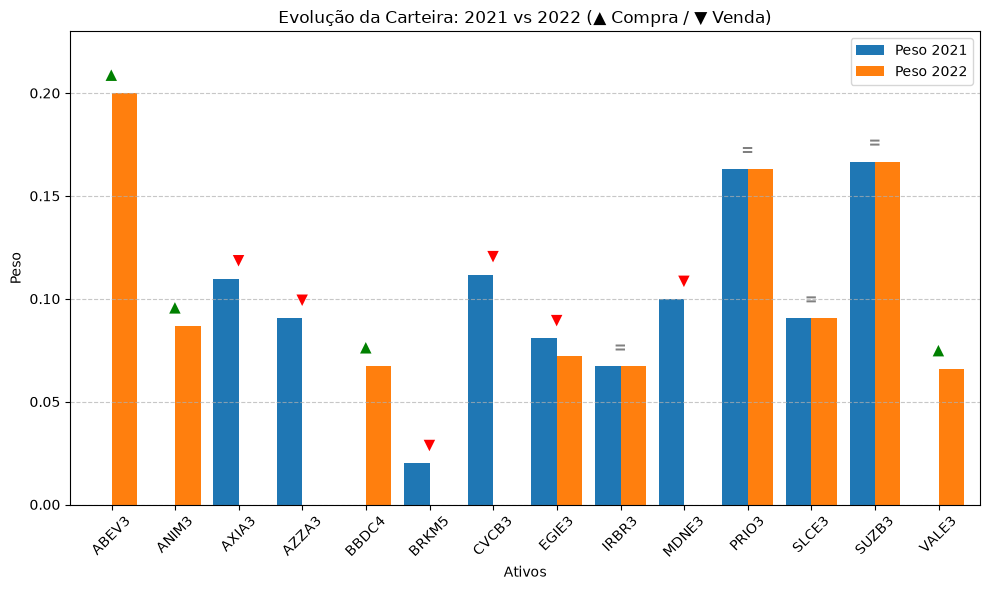

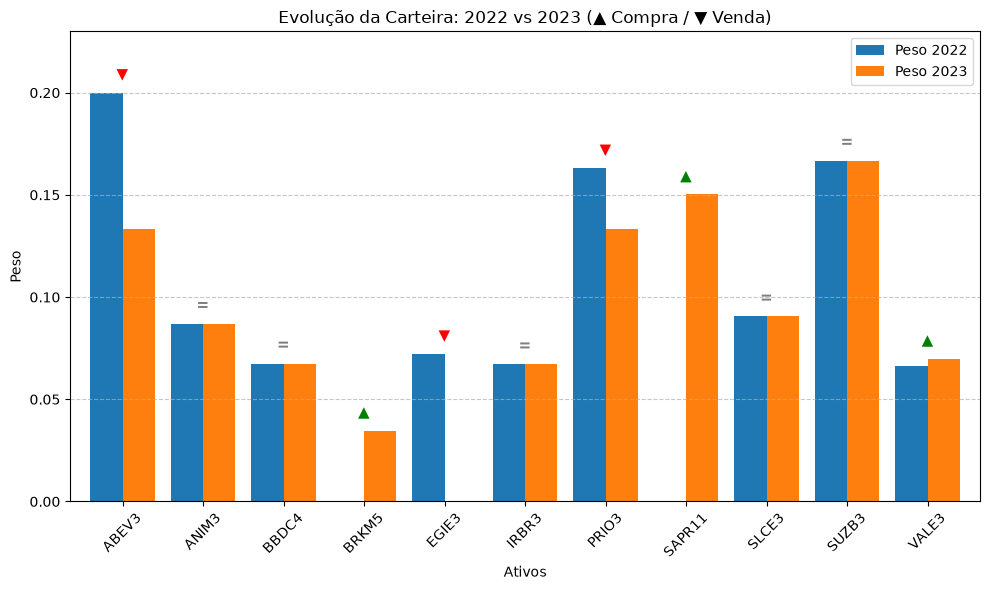

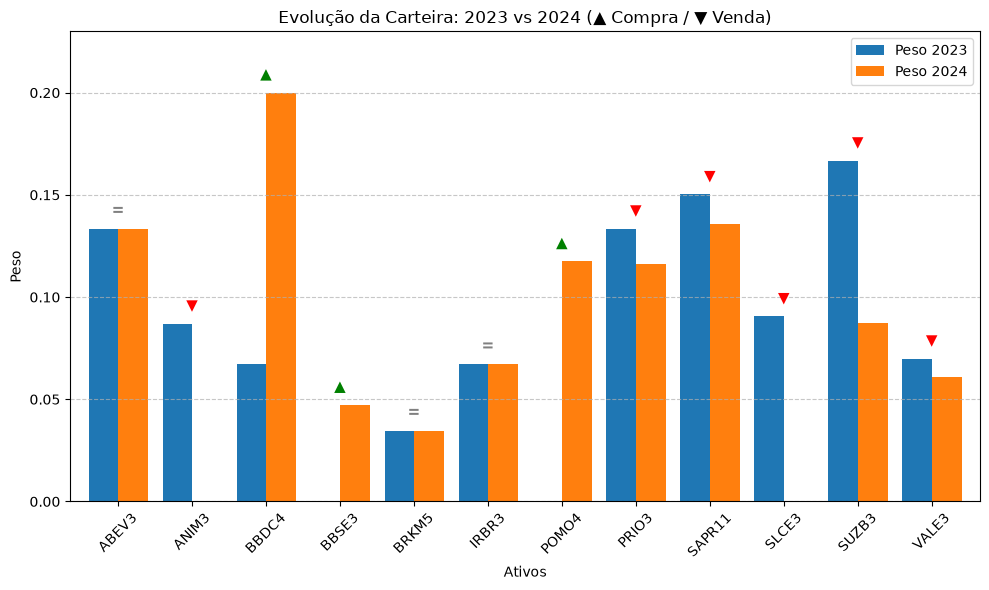

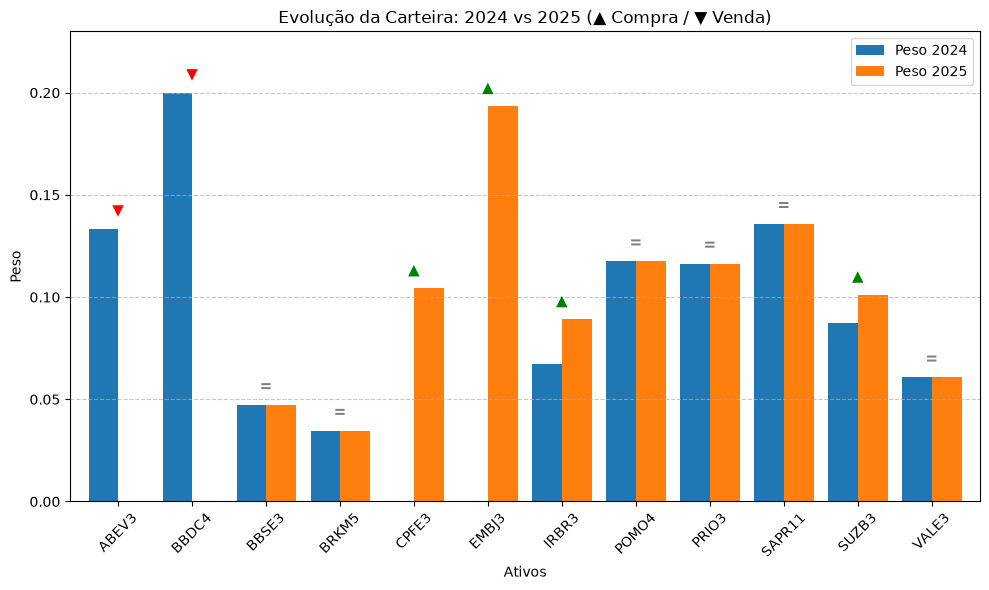

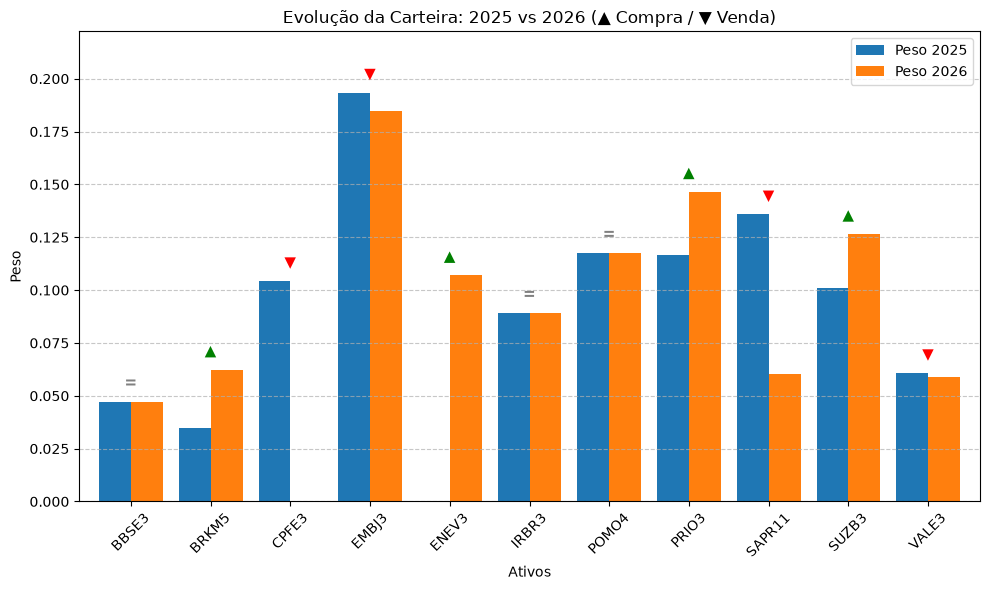

In [18]:
dicio_um = {}
for an in anos:
    ano = an.split('-',)[0]
    ativos = df_portfolios[df_portfolios['ano'] == int(ano)+1].sort_values('peso', ascending=False)['ativo'].values.tolist()
    # print(f'{ano}->{ativos}')
    pesos = df_portfolios[df_portfolios['ano'] == int(ano)+1].sort_values('peso', ascending=False)['peso'].values.tolist()
    # print(f'{ano}->{pesos}')

    dicio_um[int(ano)+1] = {ativos[j]:pesos[j] for j in range(len(ativos))}

    #plotar grafico das carteiras (postando a do ano atual e ano anterior)
    if ano == '2015':
        pass
    # elif ano == '2016':
    #     pass
    else:
        # 1. Filtrar e ordenar os dados do ano atual (ano+1 com base na sua lógica)
        df_atual = df_portfolios[df_portfolios['ano'] == int(ano)][['ativo', 'peso']]
        df_atual = df_atual.rename(columns={'peso': f'Peso {int(ano) }'})

        # 2. Filtrar e ordenar os dados do ano anterior
        df_anterior = df_portfolios[df_portfolios['ano'] == int(ano) - 1][['ativo', 'peso']]
        df_anterior = df_anterior.rename(columns={'peso': f'Peso {int(ano) - 1}'})

        # 3. Cruzar os dados pelo 'ativo' para garantir o alinhamento perfeito
        df_comparativo = df_atual.merge(df_anterior, on='ativo', how='outer').fillna(0)
        df_comparativo.set_index('ativo', inplace=True)
        
        # === ALTERADO: Inverte a ordem das colunas para colocar o ano anterior na esquerda ===
        df_comparativo = df_comparativo[[f'Peso {int(ano) - 1}', f'Peso {int(ano)}']]
        
        # 4. Plotar o gráfico de barras agrupadas lado a lado
        ax = df_comparativo.plot(kind='bar', figsize=(10, 6), width=0.8)
        
        # Bloco para adicionar as setas de compra e venda
        for i, (ativo, row) in enumerate(df_comparativo.iterrows()):
            # === ALTERADO: Ajustado para ler as colunas na nova ordem estruturada do DataFrame ===
            v_anterior = row[f'Peso {int(ano) - 1}']
            v_atual = row[f'Peso {int(ano)}']
            
            if v_atual > v_anterior:
                txt, cor = "▲", "green"
            elif v_atual < v_anterior:
                txt, cor = "▼", "red"
            else:
                txt, cor = "=", "gray"
                
            altura_max = max(v_atual, v_anterior)
            ax.text(i, altura_max + 0.005, txt, ha='center', va='bottom', color=cor, fontsize=11, fontweight='bold')
        
        # Dá uma folga de 15% no topo do eixo Y para a seta não sumir
        ax.set_ylim(0, df_comparativo.max().max() * 1.15)

        plt.title(f"Evolução da Carteira: {int(ano)-1} vs {int(ano)} (▲ Compra / ▼ Venda)")
        plt.ylabel("Peso")
        plt.xlabel("Ativos")
        plt.xticks(rotation=45)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()


In [12]:
df_portfolios.to_csv('../carteiras/carteiras_minvar.csv')
